In [1]:
import librosa
import IPython.display as ipd
import numpy as np
import scipy.fft as fft
from scipy.signal import stft, istft
import soundfile as sf
import matplotlib.pyplot as plt

In [2]:
filename = '../../data/tomsdiner_mono.wav'
diner, srate = librosa.load(filename)
ipd.Audio(diner, rate=srate)

## PEAK MAGNITUDE FILTERING

filtering based on FFT bin magnitude peaks; highest, lowest, within a window, randomly, and across frames using STFT.

In [3]:
# Filter all but the k highest (or lowest) FFT bins
def filter_high_low_mag_peaks(input, k, highest):
    complex_spectrum = fft.rfft(input)
    magnitude_spectrum = np.abs(complex_spectrum)
    sorted_mag_spectrum = np.sort(magnitude_spectrum)
    if not highest:
        sorted_mag_spectrum = np.flip(sorted_mag_spectrum)
    threshold = sorted_mag_spectrum[-k]
    if highest:
        magnitude_spectrum[magnitude_spectrum < threshold] = 0
    else:
        magnitude_spectrum[magnitude_spectrum > threshold] = 0
    num_bins = len(magnitude_spectrum)
    phase_spectrum = np.angle(complex_spectrum)
    reconstructed_complex_spectrum  = magnitude_spectrum*(np.cos(phase_spectrum)+1j*np.sin(phase_spectrum))
    reconstructed = fft.irfft(reconstructed_complex_spectrum)
    return reconstructed

# Filter all FFT bins between lo and hi
def window_reconstruct(input, lo, hi):
    complex_spectrum = fft.rfft(input)
    magnitude_spectrum = np.abs(complex_spectrum)
    sorted_mag_spectrum_indices = np.flip(np.argsort(magnitude_spectrum))
    mask = np.zeros(len(complex_spectrum), bool)
    mask[sorted_mag_spectrum_indices[lo:hi]] = True
    return fft.irfft(complex_spectrum * mask, n=len(input))

# Filter FFT bins randomly
def weighted_random_reconstruct(input, k):
    rng = np.random.default_rng()
    complex_spectrum = np.fft.rfft(input)
    magnitude_spectrum = np.abs(complex_spectrum)

    weights = magnitude_spectrum
    weights[0] = 0
    p = weights / weights.sum()

    idx = rng.choice(len(complex_spectrum), size=k, replace=False, p=p)

    mask = np.zeros(len(complex_spectrum), dtype=bool)
    mask[idx] = True
    return np.fft.irfft(complex_spectrum * mask, n=len(input))

# Filter all but the k highest FFT bins for each frame (frame size determined by nperseg)
def stft_topk(input, k, nperseg=2**15):
    f, t, Z = stft(input, srate, nperseg=nperseg)
    mag = np.abs(Z)
    idx = np.argpartition(mag, -k, axis=0)[-k:]
    mask = np.zeros_like(mag, dtype=bool)
    np.put_along_axis(mask, idx, True, axis=0)
    _, y = istft(Z * mask, srate, nperseg=nperseg)
    return y

def filter_mag_peaks(input, lim, strategy='highest', arg2=None):
    if strategy == 'highest' or strategy == 'lowest':
        highest = strategy == 'highest'
        return filter_high_low_mag_peaks(input, lim, highest=highest)
    elif strategy == 'window':
        return window_reconstruct(input, lim, arg2)
    elif strategy == 'random':
        return weighted_random_reconstruct(input, lim)
    elif strategy == 'frames':
        return stft_topk(input, lim, nperseg=arg2)
        


high_peak_diner = filter_mag_peaks(diner[0:4*srate], 50)
low_peak_diner = filter_mag_peaks(diner[0:4*srate], 10000, strategy='lowest')
window_peak_diner = filter_mag_peaks(diner[0:4*srate], 100, arg2=400, strategy='window')
random_peak_diner = filter_mag_peaks(diner[0:4*srate], 50, strategy='random')
frame_peak_diner = filter_mag_peaks(diner[0:4*srate], 100, arg2=2**15, strategy='frames')

sf.write("high_peak_diner.wav", high_peak_diner / np.max(np.abs(high_peak_diner)), srate)
sf.write("low_peak_diner.wav", low_peak_diner / np.max(np.abs(low_peak_diner)), srate)
sf.write("window_peak_diner.wav", window_peak_diner / np.max(np.abs(window_peak_diner)), srate)
sf.write("random_peak_diner.wav", random_peak_diner / np.max(np.abs(random_peak_diner)), srate)
sf.write("frame_peak_diner.wav", frame_peak_diner / np.max(np.abs(frame_peak_diner)), srate)

ipd.display(ipd.Audio(high_peak_diner, rate=srate, normalize=True))
ipd.display(ipd.Audio(low_peak_diner, rate=srate, normalize=True))
ipd.display(ipd.Audio(window_peak_diner, rate=srate, normalize=True))
ipd.display(ipd.Audio(random_peak_diner, rate=srate, normalize=True))
ipd.display(ipd.Audio(frame_peak_diner, rate=srate, normalize=True))

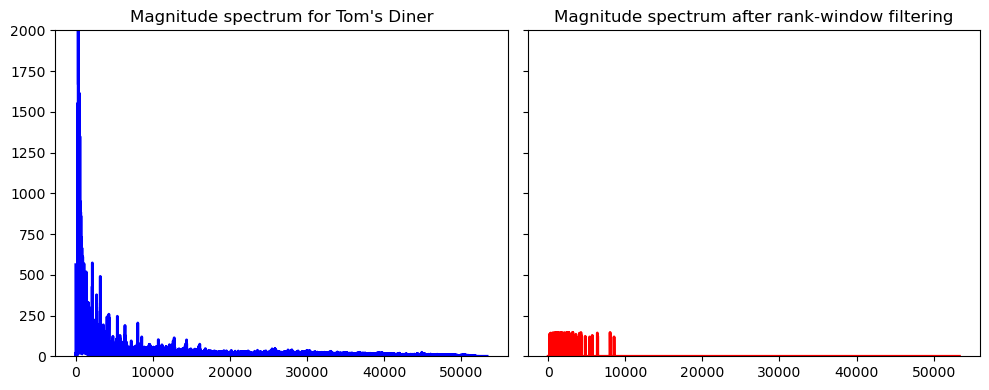

In [13]:
def window_reconstruct(input, lo, hi):
    complex_spectrum = fft.rfft(input)
    magnitude_spectrum = np.abs(complex_spectrum)
    sorted_mag_spectrum_indices = np.flip(np.argsort(magnitude_spectrum))
    mask = np.zeros(len(complex_spectrum), bool)
    mask[sorted_mag_spectrum_indices[lo:hi]] = True
    return magnitude_spectrum * mask

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

ax1.set_title("Magnitude spectrum for Tom's Diner")
ax1.plot(np.abs(fft.rfft(diner)), lw=2, color='blue')

ax2.set_title("Magnitude spectrum after rank-window filtering")
ax2.plot(window_reconstruct(diner, 1000, 1300), lw=2, color='red')

ax1.set_ylim(0, 2000)   # applies to both axes because sharey=True
plt.tight_layout()
plt.show()